In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)


In [2]:
df = pd.read_csv("../dataset/heart_disease_dataset.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)


First 5 rows:
   Age  Gender  Cholesterol  Blood Pressure  Heart Rate  Smoking  \
0   75  Female          228             119          66  Current   
1   48    Male          204             165          62  Current   
2   53    Male          234              91          67    Never   
3   69  Female          192              90          72  Current   
4   62  Female          172             163          93    Never   

  Alcohol Intake  Exercise Hours Family History Diabetes Obesity  \
0          Heavy               1             No       No     Yes   
1            NaN               5             No       No      No   
2          Heavy               3            Yes       No     Yes   
3            NaN               4             No      Yes      No   
4            NaN               6             No      Yes      No   

   Stress Level  Blood Sugar Exercise Induced Angina   Chest Pain Type  \
0             8          119                     Yes   Atypical Angina   
1             9     

In [3]:
X = df.drop("Heart Disease", axis=1)
y = df["Heart Disease"]

print("\nFeatures:")
print(X.columns)

print("\nTarget:")
print(y.name)



Features:
Index(['Age', 'Gender', 'Cholesterol', 'Blood Pressure', 'Heart Rate',
       'Smoking', 'Alcohol Intake', 'Exercise Hours', 'Family History',
       'Diabetes', 'Obesity', 'Stress Level', 'Blood Sugar',
       'Exercise Induced Angina', 'Chest Pain Type'],
      dtype='str')

Target:
Heart Disease


In [4]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns

numerical_columns = X.select_dtypes(
    exclude=["object"]
).columns

print("\nCategorical Columns:")
print(list(categorical_columns))

print("\nNumerical Columns:")
print(list(numerical_columns))



Categorical Columns:
['Gender', 'Smoking', 'Alcohol Intake', 'Family History', 'Diabetes', 'Obesity', 'Exercise Induced Angina', 'Chest Pain Type']

Numerical Columns:
['Age', 'Cholesterol', 'Blood Pressure', 'Heart Rate', 'Exercise Hours', 'Stress Level', 'Blood Sugar']


E:\temp\ipykernel_22240\1427491433.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(


In [5]:
imputer = SimpleImputer(strategy="most_frequent")

X[categorical_columns] = imputer.fit_transform(
    X[categorical_columns]
)

print("\nMissing values after imputation:")
print(X.isnull().sum())



Missing values after imputation:
Age                        0
Gender                     0
Cholesterol                0
Blood Pressure             0
Heart Rate                 0
Smoking                    0
Alcohol Intake             0
Exercise Hours             0
Family History             0
Diabetes                   0
Obesity                    0
Stress Level               0
Blood Sugar                0
Exercise Induced Angina    0
Chest Pain Type            0
dtype: int64


In [6]:
label_encoders = {}

for column in categorical_columns:

    encoder = LabelEncoder()

    X[column] = encoder.fit_transform(
        X[column]
    )

    label_encoders[column] = encoder


print("\nData after Label Encoding:")
print(X.head())



Data after Label Encoding:
   Age  Gender  Cholesterol  Blood Pressure  Heart Rate  Smoking  \
0   75       0          228             119          66        0   
1   48       1          204             165          62        0   
2   53       1          234              91          67        2   
3   69       0          192              90          72        0   
4   62       0          172             163          93        2   

   Alcohol Intake  Exercise Hours  Family History  Diabetes  Obesity  \
0               0               1               0         0        1   
1               0               5               0         0        0   
2               0               3               1         0        1   
3               0               4               0         1        0   
4               0               6               0         1        0   

   Stress Level  Blood Sugar  Exercise Induced Angina  Chest Pain Type  
0             8          119                        1    

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data:", X_train.shape)
print("Testing data :", X_test.shape)



Training data: (800, 15)
Testing data : (200, 15)


In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


In [9]:
# minmax_scaler = MinMaxScaler()

# X_train_scaled = minmax_scaler.fit_transform(X_train)

# X_test_scaled = minmax_scaler.transform(X_test)


In [10]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
model.fit(
    X_train_scaled,
    y_train
)

print("\nLogistic Regression model trained successfully.")



Logistic Regression model trained successfully.


In [11]:
y_pred = model.predict(X_test_scaled)
# Probability of class 1
y_probability = model.predict_proba(X_test_scaled)[:, 1]


In [12]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)


print("\n================================")
print("CLASSIFICATION METRICS")
print("================================")

print("Accuracy  :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1 Score  :", round(f1, 4))



CLASSIFICATION METRICS
Accuracy  : 0.865
Precision : 0.8493
Recall    : 0.7949
F1 Score  : 0.8212


In [13]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)



Confusion Matrix:
[[111  11]
 [ 16  62]]


In [14]:
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred
    )
)



Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.91      0.89       122
           1       0.85      0.79      0.82        78

    accuracy                           0.86       200
   macro avg       0.86      0.85      0.86       200
weighted avg       0.86      0.86      0.86       200




ROC-AUC Score:

 0.9505


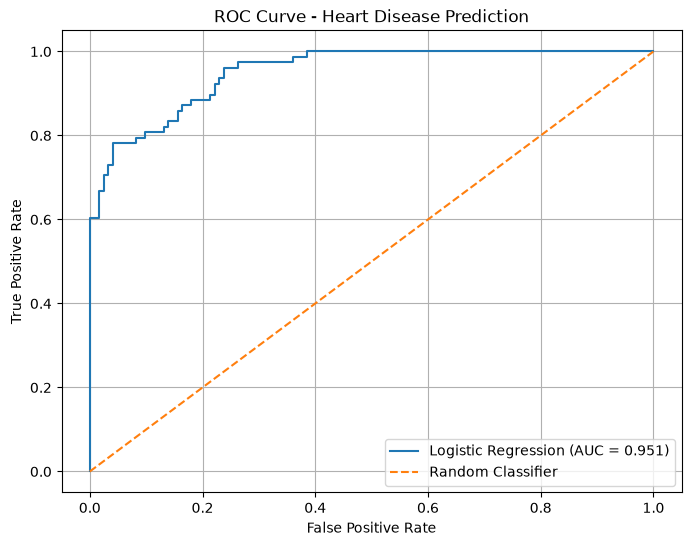

In [15]:
# ============================================
# 15. ROC Curve
# ============================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)


# ============================================
# 16. Calculate AUC
# ============================================

roc_auc = auc(
    fpr,
    tpr
)

print("\nROC-AUC Score:",
      round(roc_auc, 4))


# ============================================
# 17. Plot ROC Curve
# ============================================

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label="Logistic Regression (AUC = {:.3f})".format(
        roc_auc
    )
)

# Random classifier line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve - Heart Disease Prediction"
)

plt.legend()

plt.grid()
